In [2]:
%load_ext cudf.pandas
%load_ext cuml.accel
import pandas as pd
import numpy as np
import pickle
import os
import sys

from sklearn.metrics import accuracy_score

from sklearn import metrics
from joblib import dump

# librosa is a Python library for analyzing audio and music. It can be used to extract the data from the audio files we will see it later.
import librosa
import librosa.display
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

# to play the audio files
from IPython.display import Audio

The cudf.pandas extension is already loaded. To reload it, use:
  %reload_ext cudf.pandas
The cuml.accel extension is already loaded. To reload it, use:
  %reload_ext cuml.accel


In [3]:
Ravdess = "Audio_Speech_Actors_01-24/"
ravdess_directory_list = os.listdir(Ravdess)

In [4]:
#ravdess_directory_list = os.listdir(Ravdess)

file_emotion = []
file_path = []
for dir in ravdess_directory_list:
    # as their are 20 different actors in our previous directory we need to extract files for each actor.
    actor = os.listdir(Ravdess + dir)
    #print(actor,"->actor")
    for file in actor:
        part = file.split('.')
        #print(file,"->file")
        #print(part,"-1st split")
        part = part[0].split('-')
        #print(part,"-2nd split")
        # third part in each file represents the emotion associated to that file.
        file_emotion.append(int(part[2]))
        file_path.append(Ravdess + dir + '/' + file)

    #print(file_emotion);print(file_path)

In [5]:
# dataframe for emotion of files
emotion_df = pd.DataFrame(file_emotion, columns=['Emotions'])

# dataframe for path of files.
path_df = pd.DataFrame(file_path, columns=['Path'])
Ravdess_df = pd.concat([emotion_df, path_df],axis=1)

# changing integers to actual emotions.
Ravdess_df['Emotions'].replace([1,2,3,4,5,6,7,8],['neutral','calm','happy','sad','angry','fear','disgust','surprise'], inplace=True)
Ravdess_df.head(10)

,Emotions,Path
0,1,Audio_Speech_Actors_01-24/Actor_01/03-01-01-01...
1,1,Audio_Speech_Actors_01-24/Actor_01/03-01-01-01...
2,1,Audio_Speech_Actors_01-24/Actor_01/03-01-01-01...
3,1,Audio_Speech_Actors_01-24/Actor_01/03-01-01-01...
4,2,Audio_Speech_Actors_01-24/Actor_01/03-01-02-01...
5,2,Audio_Speech_Actors_01-24/Actor_01/03-01-02-01...
6,2,Audio_Speech_Actors_01-24/Actor_01/03-01-02-01...
7,2,Audio_Speech_Actors_01-24/Actor_01/03-01-02-01...
8,2,Audio_Speech_Actors_01-24/Actor_01/03-01-02-02...
9,2,Audio_Speech_Actors_01-24/Actor_01/03-01-02-02...


In [6]:
def noise(data):
    noise_amp = 0.035*np.random.uniform()*np.amax(data)
    data = data + noise_amp*np.random.normal(size=data.shape[0])
    return data

def stretch(data, rate=0.8):
    return librosa.effects.time_stretch(data, rate=rate)

def pitch(data, sampling_rate, pitch_factor=0.7):
    return librosa.effects.pitch_shift(y=data, sr=sampling_rate, n_steps=int(pitch_factor))

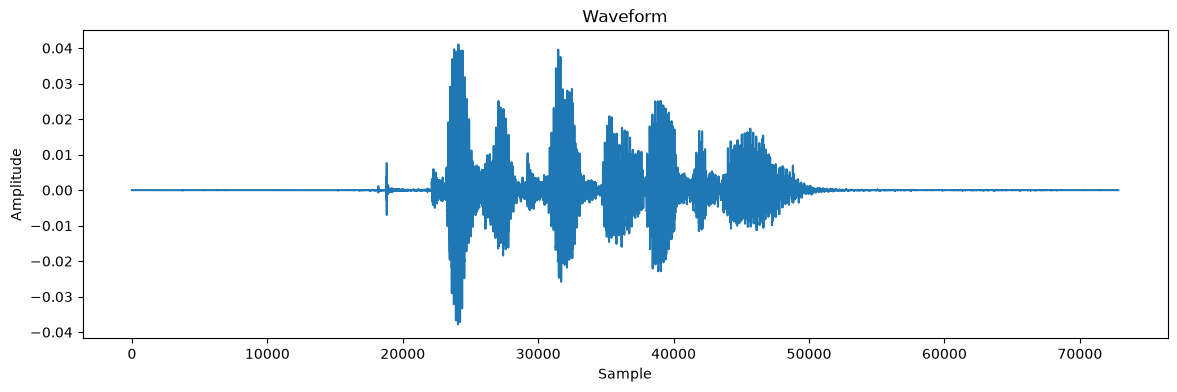

In [7]:
#1.Actual Audio
path = 'Audio_Speech_Actors_01-24/Actor_01/03-01-01-01-01-01-01.wav'
data, sample_rate = librosa.load(path)

# Plot waveform
plt.figure(figsize=(14, 4))
plt.plot(data)
plt.title('Waveform')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.show()

#Audio preview
Audio(path)

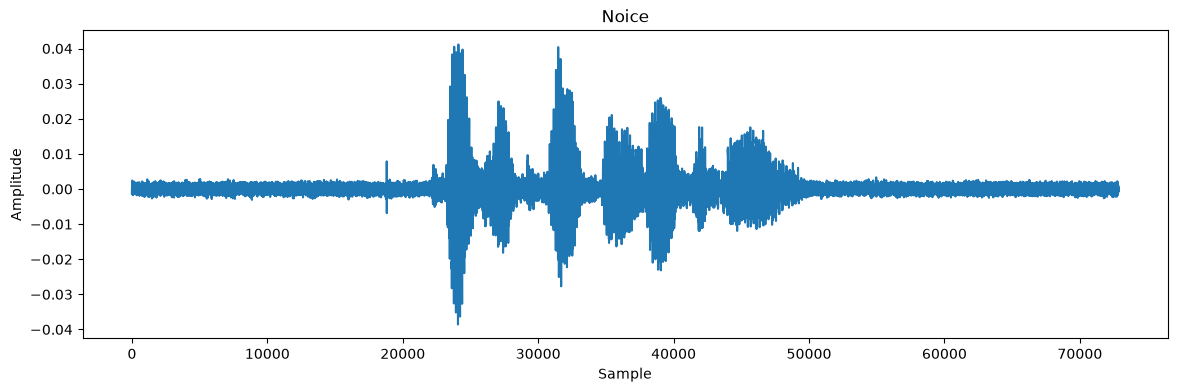

In [8]:
#2Noise injection
data, sample_rate = librosa.load(path)
x = noise(data)

# Plot waveform
plt.figure(figsize=(14, 4))
plt.plot(x)
plt.title('Noice')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.show()

#Audio preview
Audio(path)

/home/abhinav/Documents/Machine-Learning-Models/Sound-Emotion-Recognition/.venv/lib/python3.12/site-packages/librosa/effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/home/abhinav/Documents/Machine-Learning-Models/Sound-Emotion-Recognition/.venv/lib/python3.12/site-packages/librosa/effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(


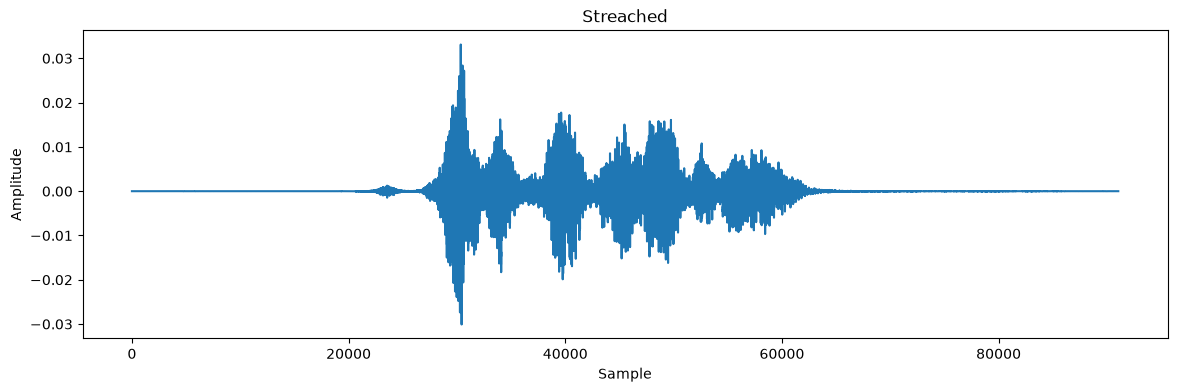

In [9]:
#3.Streatching
x = stretch(data)
data, sample_rate = librosa.load(path)

# Plot waveform
plt.figure(figsize=(14, 4))
plt.plot(x)
plt.title('Streached')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.show()

#Audio preview
Audio(path)

/home/abhinav/Documents/Machine-Learning-Models/Sound-Emotion-Recognition/.venv/lib/python3.12/site-packages/librosa/effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
/home/abhinav/Documents/Machine-Learning-Models/Sound-Emotion-Recognition/.venv/lib/python3.12/site-packages/librosa/effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(


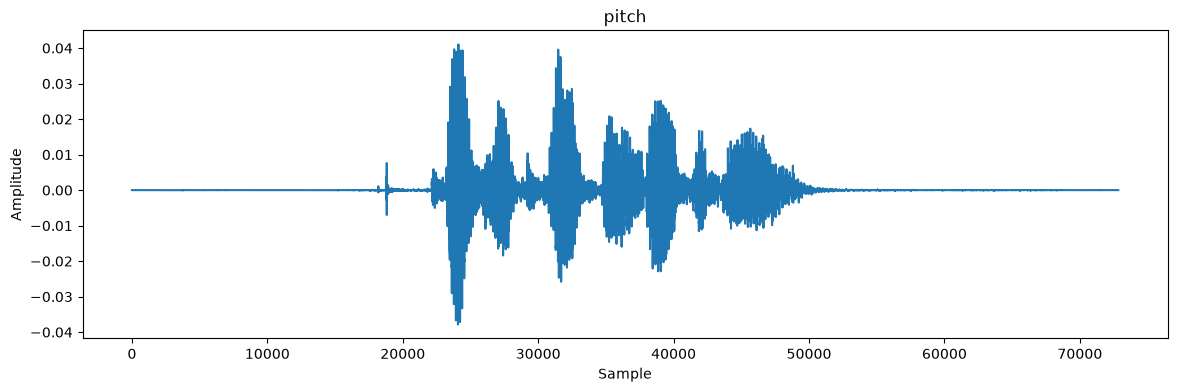

In [10]:
#4.Pitch
x = pitch(data, sample_rate)
data, sample_rate = librosa.load(path)

# Plot waveform
plt.figure(figsize=(14, 4))
plt.plot(x)
plt.title('pitch')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.show()

#Audio preview
Audio(path)

In [11]:
def extract_features(data, sample_rate):
    result = np.array([])  # Initialize result as an empty array
    # MFCC
    mfcc = np.mean(librosa.feature.mfcc(y=data, sr=sample_rate).T, axis=0)
    result = np.hstack((result, mfcc)) # stacking horizontally

    # Root Mean Square Value
    rms = np.mean(librosa.feature.rms(y=data).T, axis=0)
    result = np.hstack((result, rms))

    # MelSpectogram
    mel = np.mean(librosa.feature.melspectrogram(y=data, sr=sample_rate).T, axis=0)
    result = np.hstack((result, mel))

    # ZCR
    zcr = np.mean(librosa.feature.zero_crossing_rate(y=data).T, axis=0)
    result = np.hstack((result, zcr)) # stacking horizontally

    # Chroma_stft
    stft = np.abs(librosa.stft(data))
    chroma_stft = np.mean(librosa.feature.chroma_stft(S=stft, sr=sample_rate).T, axis=0)
    result = np.hstack((result, chroma_stft)) # stacking horizontally

    #contrast
    contrast = np.mean(librosa.feature.spectral_contrast(S=stft, sr=sample_rate).T,axis=0)
    result = np.hstack((result, contrast))


    return result

In [12]:
def get_features(path):
    # duration and offset are used to take care of the no audio in start and the ending of each audio files as seen above.
    data, sample_rate = librosa.load(path, duration=2.5, offset=0.6)

    # without augmentation
    res1 = extract_features(data,sample_rate)
    result = np.array(res1)

    # data with noise
    noise_data = noise(data)
    res2 = extract_features(noise_data,sample_rate)
    result = np.vstack((result, res2)) # stacking vertically

    # data with stretching and pitching
    new_data = stretch(data)
    data_stretch_pitch = pitch(new_data, sample_rate)
    res3 = extract_features(data_stretch_pitch,sample_rate)
    result = np.vstack((result, res3)) # stacking vertically

    return result

In [18]:
from joblib import Parallel, delayed

def process_single_row(path, emotion):
    # Extract features (returns a list of 3 feature arrays due to augmentation)
    features = get_features(path) 
    # Pair each of the 3 augmented features with the same emotion
    return [(feat, emotion) for feat in features]

# Run in parallel using all available CPU cores (-1)
results = Parallel(n_jobs=-1)(
    delayed(process_single_row)(path, emotion) 
    for path, emotion in zip(Ravdess_df.Path, Ravdess_df.Emotions)
)

# Flatten the list of lists into X and Y arrays
# Each item in 'results' is a list of 3 tuples: [(feat1, emo), (feat2, emo), (feat3, emo)]
X = [item[0] for sublist in results for item in sublist]
Y = [item[1] for sublist in results for item in sublist]

Error processing line 2 of /home/abhinav/Documents/Machine-Learning-Models/Sound-Emotion-Recognition/.venv/lib/python3.12/site-packages/_zz_cuml_accel.pth:

Error processing line 2 of /home/abhinav/Documents/Machine-Learning-Models/Sound-Emotion-Recognition/.venv/lib/python3.12/site-packages/_zz_cuml_accel.pth:

Error processing line 2 of /home/abhinav/Documents/Machine-Learning-Models/Sound-Emotion-Recognition/.venv/lib/python3.12/site-packages/_zz_cuml_accel.pth:
Error processing line 2 of /home/abhinav/Documents/Machine-Learning-Models/Sound-Emotion-Recognition/.venv/lib/python3.12/site-packages/_zz_cuml_accel.pth:


Error processing line 2 of /home/abhinav/Documents/Machine-Learning-Models/Sound-Emotion-Recognition/.venv/lib/python3.12/site-packages/_zz_cuml_accel.pth:

Error processing line 2 of /home/abhinav/Documents/Machine-Learning-Models/Sound-Emotion-Recognition/.venv/lib/python3.12/site-packages/_zz_cuml_accel.pth:

  Traceback (most recent call last):
    File "<frozen sit

In [ ]:
X, Y = [], []
for path, emotion in zip(Ravdess_df.Path, Ravdess_df.Emotions):
    feature = get_features(path)
    for ele in feature:
        X.append(ele)
        # appending emotion 3 times as we have made 3 augmentation techniques on each audio file.
        Y.append(emotion)
    #print(path)


In [19]:
Features = pd.DataFrame(X)
Features['Emotions'] = Y
Features.to_csv('features.csv', index=False)
Features.head()

,0,1,2,3,4,5,6,7,8,9,...,160,161,162,163,164,165,166,167,168,Emotions
0,-645.880737,72.619637,0.841305,16.399446,10.241591,0.653903,-4.328002,-4.258933,-14.575824,-3.806285,...,0.717019,0.668645,21.719021,11.853675,15.942501,15.102606,15.750957,17.976804,46.206417,1
1,-519.799065,46.893745,4.871030,11.789622,7.490666,-1.172722,-3.889203,-7.263363,-11.928391,-6.148697,...,0.728389,0.695961,18.731472,11.998115,15.750632,14.450208,14.979939,15.662869,13.911352,1
2,-668.460510,69.924965,-0.438427,16.162754,9.303123,0.199859,-5.412356,-4.951262,-14.789142,-4.063044,...,0.699904,0.659187,22.968635,12.931455,17.279609,16.187969,17.059452,19.672799,46.570769,1
3,-634.663269,72.324059,-2.998577,20.209738,10.674219,-1.151012,-2.813592,-7.923956,-16.231960,-2.627547,...,0.724930,0.702074,23.183852,13.007365,17.096784,15.801211,15.745660,17.866518,45.749270,1
4,-448.888346,29.956683,8.699754,10.974374,5.816533,-1.174913,-2.867806,-7.748184,-9.839344,-4.881488,...,0.769770,0.737365,17.575906,13.072290,15.850395,14.666159,14.323671,14.689922,13.482966,1


In [20]:
#Encoding output vector
encoder = OneHotEncoder()
Y = encoder.fit_transform(np.array(Y).reshape(-1,1)).toarray()

In [21]:
X = Features.drop('Emotions',axis=1).values
Y = encoder.transform(Features['Emotions'].to_numpy().reshape(-1, 1)).toarray()

In [22]:
# splitting data
x_train, x_test, y_train, y_test = train_test_split(X, Y, random_state=0, shuffle=True,stratify=Y)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((3240, 169), (3240, 8), (1080, 169), (1080, 8))

In [23]:
# scaling our data with sklearn's Standard scaler
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((3240, 169), (3240, 8), (1080, 169), (1080, 8))

In [26]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

In [27]:
model = Sequential([
    tf.keras.Input(shape=(x_train.shape[1],)),
    Dense(256, activation="relu"),
    BatchNormalization(),
    Dropout(0.3),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(y_train.shape[1], activation="softmax")
])



In [32]:
from tensorflow.keras.callbacks import EarlyStopping

model.compile(optimizer=Adam(learning_rate=1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    min_delta=1e-4,
    restore_best_weights=True,
    verbose=1,
)
history = model.fit(
    x_train,
    y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1,
)


Epoch 1/30


81/81 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.7998 - loss: 0.5566 - val_accuracy: 0.7762 - val_loss: 0.6539
Epoch 2/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8241 - loss: 0.5022 - val_accuracy: 0.7747 - val_loss: 0.6170
Epoch 3/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8167 - loss: 0.5187 - val_accuracy: 0.7793 - val_loss: 0.6175
Epoch 4/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8229 - loss: 0.5025 - val_accuracy: 0.7948 - val_loss: 0.5921
Epoch 5/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8179 - loss: 0.5113 - val_accuracy: 0.8225 - val_loss: 0.5768
Epoch 6/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8314 - loss: 0.4797 - val_accuracy: 0.8025 - val_loss: 0.5820
Epoch 7/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8345 - loss: 0.4626 - val_accuracy: 0.8025 - val_loss: 0.5786
Epoch 8/30
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8318 - loss: 0.4583 - val_accuracy: 0.8148 - val_loss: 0.5562
Ep

In [33]:
y_pred = np.argmax(model.predict(x_test, verbose=0), axis=1)
y_test_labels = np.argmax(y_test, axis=1)

In [34]:
#Generating Classification Report
accuracy = metrics.accuracy_score(y_test_labels, y_pred)
report = metrics.classification_report(y_test_labels, y_pred)  # Generating classification report
print(f"The Accuracy Score With Linear Kernel is: {accuracy}")
print(f"The classification Report: \n{report}")

The Accuracy Score With Linear Kernel is: 0.8546296296296296
The classification Report: 
              precision    recall  f1-score   support

           0       0.73      0.71      0.72        72
           1       0.90      0.91      0.91       144
           2       0.83      0.83      0.83       144
           3       0.84      0.84      0.84       144
           4       0.86      0.94      0.90       144
           5       0.87      0.84      0.86       144
           6       0.86      0.81      0.84       144
           7       0.89      0.88      0.89       144

    accuracy                           0.85      1080
   macro avg       0.85      0.85      0.85      1080
weighted avg       0.85      0.85      0.85      1080



In [35]:
#Prediton on test data
df = pd.DataFrame(columns=['Predicted Labels', 'Actual Labels'])
df['Predicted Labels'] = encoder.categories_[0][y_pred]
df['Actual Labels'] = encoder.categories_[0][y_test_labels]

df.head(10)

,Predicted Labels,Actual Labels
0,7,7
1,6,4
2,6,6
3,3,3
4,8,3
5,8,8
6,8,8
7,4,4
8,5,5
9,3,3


In [36]:
#saving file as .pkl file
model.save("sound_emotion_model.keras")